In [65]:
import os
import re
from transformers import pipeline

In [66]:
with open('claude_training_overview.txt',"r",encoding='utf-8') as file:
  content = file.read()
  print(content)

I'm Claude, made by Anthropic, and I don't have access to Anthropic's internal training code, datasets, or hyperparameters, so I can only describe what has been shared publicly plus general background on the techniques. Publicly, Claude models are trained in stages: first pretraining on a very large corpus, which Anthropic's system cards describe as a mix of publicly available web data gathered by a crawler that follows robots.txt and avoids password-protected pages, non-public data licensed from third parties, data from users who opted in, and synthetic data, though the exact composition, size, and filtering have not been published. In pretraining, the model learns to predict the next token, which in general terms means minimizing a cross-entropy loss, the average negative log-probability of each token given the ones before it. After that comes post-training, where the model is shaped into a helpful, honest, and harmless assistant using supervised fine-tuning on good example responses

In [67]:
print(content.split('.'))

["I'm Claude, made by Anthropic, and I don't have access to Anthropic's internal training code, datasets, or hyperparameters, so I can only describe what has been shared publicly plus general background on the techniques", " Publicly, Claude models are trained in stages: first pretraining on a very large corpus, which Anthropic's system cards describe as a mix of publicly available web data gathered by a crawler that follows robots", 'txt and avoids password-protected pages, non-public data licensed from third parties, data from users who opted in, and synthetic data, though the exact composition, size, and filtering have not been published', ' In pretraining, the model learns to predict the next token, which in general terms means minimizing a cross-entropy loss, the average negative log-probability of each token given the ones before it', " After that comes post-training, where the model is shaped into a helpful, honest, and harmless assistant using supervised fine-tuning on good exa

In [68]:
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize , sent_tokenize
from nltk.stem import WordNetLemmatizer
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [69]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

In [70]:
def whole_preprocessing(content):
  senten_tokens = sent_tokenize(content.lower())

  word_tokens = []
  for sentence in senten_tokens:
        word_tokens.extend(word_tokenize(sentence))

  word_tokens = word_tokenize(content.lower())

  filtered_tokens = [tok for tok in word_tokens if tok not in stopwords.words('english') and tok not in string.punctuation]

  lemmatized_content = [lemmatizer.lemmatize(tok) for tok in filtered_tokens]

  return lemmatized_content

In [71]:
def preprocessing(content):


  word_tokens = word_tokenize(content)
  filtered_tokens = [tok for tok in word_tokens if tok not in string.punctuation and tok not in stopwords.words('english')]

  return" ".join(filtered_tokens)

In [72]:
content = content.lower()

In [73]:
clean_content = [preprocessing(c) for c in content.split('.')]
print(clean_content)

["'m claude made anthropic n't access anthropic 's internal training code datasets hyperparameters describe shared publicly plus general background techniques", "publicly claude models trained stages first pretraining large corpus anthropic 's system cards describe mix publicly available web data gathered crawler follows robots", 'txt avoids password-protected pages non-public data licensed third parties data users opted synthetic data though exact composition size filtering published', 'pretraining model learns predict next token general terms means minimizing cross-entropy loss average negative log-probability token given ones', "comes post-training model shaped helpful honest harmless assistant using supervised fine-tuning good example responses reinforcement learning human feedback reward preference model trained human comparisons responses commonly bradley-terry style loss model optimized score well kl penalty keeps close reference model anthropic 's published constitutional ai ap

In [74]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(clean_content)
print(vectorizer.get_feature_names_out())


['access' 'ai' 'along' 'also' 'alternative' 'anthropic' 'anything'
 'approach' 'architecture' 'assistant' 'authoritative' 'available'
 'average' 'avoids' 'background' 'best' 'bradley' 'cards' 'care'
 'character' 'claude' 'close' 'code' 'comes' 'commonly' 'comparisons'
 'composition' 'compute' 'constitution' 'constitutional' 'contents'
 'corpus' 'count' 'crawler' 'critiques' 'cross' 'data' 'datasets'
 'deliberate' 'describe' 'details' 'difference' 'direct' 'directly'
 'dispreferred' 'dpo' 'else' 'entropy' 'exact' 'example' 'feedback'
 'filtering' 'fine' 'first' 'follows' 'functions' 'gathered' 'general'
 'generated' 'given' 'good' 'guess' 'harmless' 'helpful' 'honest'
 'honesty' 'human' 'hyperparameters' 'internal' 'keeps' 'kl' 'know'
 'known' 'labels' 'large' 'learning' 'learns' 'licensed' 'like' 'log'
 'loss' 'made' 'means' 'minimizing' 'mix' 'model' 'models' 'negative'
 'next' 'non' 'ones' 'opted' 'optimization' 'optimized' 'optimizes'
 'outputs' 'pages' 'pairs' 'papers' 'parameter' 

In [75]:
print(X.toarray())

[[1 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 2 1 ... 0 0 1]
 [0 1 0 ... 1 1 0]
 [0 0 0 ... 0 0 0]]


In [76]:
import numpy as np

In [77]:
word_counts = np.sum(X.toarray(),axis=0)
word_counts

array([1, 3, 1, 1, 1, 6, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1,
       1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 4, 1, 1, 2, 1, 1, 1, 1,
       1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1,
       3, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 3, 4, 1, 1, 1, 1, 9, 1, 1,
       1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3,
       1, 2, 1, 2, 1, 1, 3, 2, 1, 2, 2, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 2, 4, 1,
       1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1])

In [78]:
word_labels = vectorizer.get_feature_names_out()
word_labels

array(['access', 'ai', 'along', 'also', 'alternative', 'anthropic',
       'anything', 'approach', 'architecture', 'assistant',
       'authoritative', 'available', 'average', 'avoids', 'background',
       'best', 'bradley', 'cards', 'care', 'character', 'claude', 'close',
       'code', 'comes', 'commonly', 'comparisons', 'composition',
       'compute', 'constitution', 'constitutional', 'contents', 'corpus',
       'count', 'crawler', 'critiques', 'cross', 'data', 'datasets',
       'deliberate', 'describe', 'details', 'difference', 'direct',
       'directly', 'dispreferred', 'dpo', 'else', 'entropy', 'exact',
       'example', 'feedback', 'filtering', 'fine', 'first', 'follows',
       'functions', 'gathered', 'general', 'generated', 'given', 'good',
       'guess', 'harmless', 'helpful', 'honest', 'honesty', 'human',
       'hyperparameters', 'internal', 'keeps', 'kl', 'know', 'known',
       'labels', 'large', 'learning', 'learns', 'licensed', 'like', 'log',
       'loss', 'made

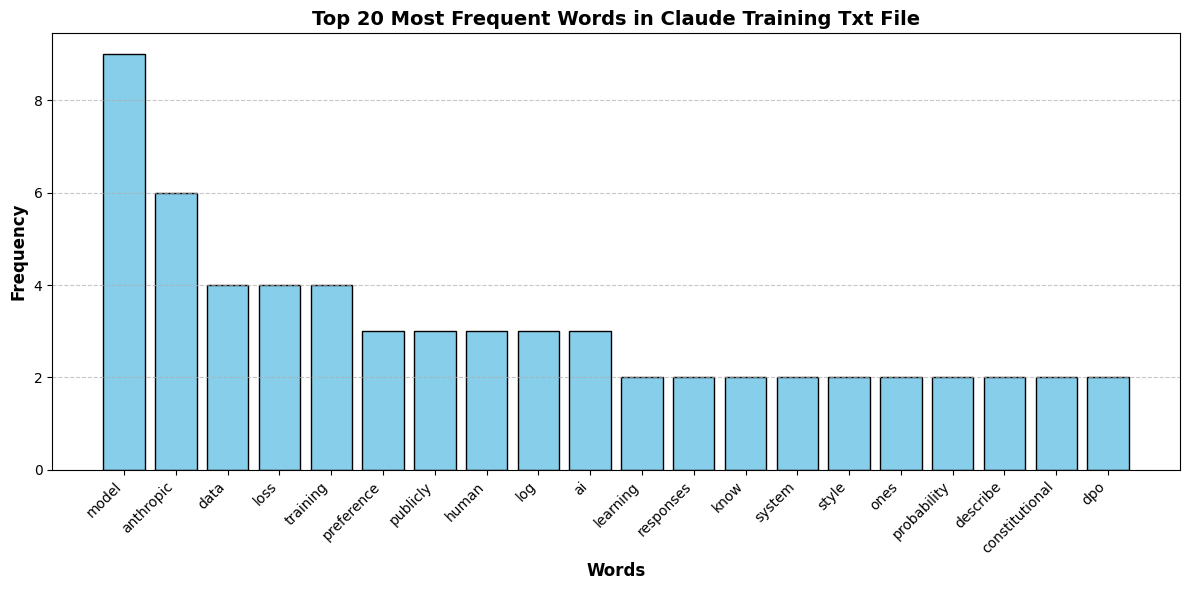

In [79]:
import matplotlib.pyplot as plt
import numpy as np


words = np.array(word_labels)
counts = np.array(word_counts)


sorted_indices = np.argsort(counts)[::-1]
top_n = 20
top_indices = sorted_indices[:top_n]

top_words = words[top_indices]
top_counts = counts[top_indices]


plt.figure(figsize=(12, 6))
plt.bar(top_words, top_counts, color='skyblue', edgecolor='black')


plt.xlabel('Words', fontsize=12, fontweight='bold')
plt.ylabel('Frequency', fontsize=12, fontweight='bold')
plt.title('Top 20 Most Frequent Words in Claude Training Txt File', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [80]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
tfidif_matrix = tfidf.fit_transform(clean_content)

print(tfidif_matrix.toarray(),end='\n\n')
print(tfidf.get_feature_names_out())

[[0.26013524 0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.18381309 0.11071932 ... 0.         0.         0.11071932]
 [0.         0.09853476 0.         ... 0.1187043  0.1187043  0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]

['access' 'ai' 'along' 'also' 'alternative' 'anthropic' 'anything'
 'approach' 'architecture' 'assistant' 'authoritative' 'available'
 'average' 'avoids' 'background' 'best' 'bradley' 'cards' 'care'
 'character' 'claude' 'close' 'code' 'comes' 'commonly' 'comparisons'
 'composition' 'compute' 'constitution' 'constitutional' 'contents'
 'corpus' 'count' 'crawler' 'critiques' 'cross' 'data' 'datasets'
 'deliberate' 'describe' 'details' 'difference' 'direct' 'directly'
 'dispreferred' 'dpo' 'else' 'entropy' 'exact' 'example' 'feedback'
 'filtering' 'fi

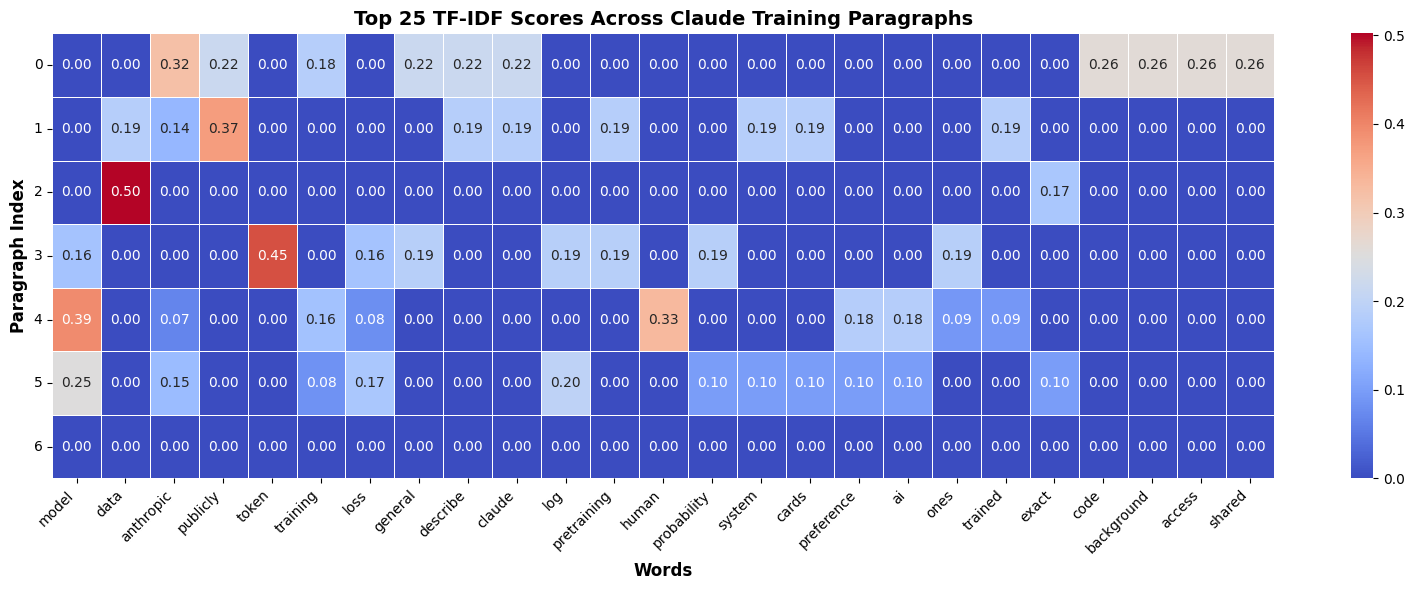

In [81]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


df_tfidf = pd.DataFrame(tfidif_matrix.toarray(), columns=tfidf.get_feature_names_out())


top_tfidf_words = df_tfidf.mean().sort_values(ascending=False).head(25).index
df_tfidf_filtered = df_tfidf[top_tfidf_words]

plt.figure(figsize=(16, 6))
sns.heatmap(df_tfidf_filtered, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, linewidths=0.5)
plt.title('Top 25 TF-IDF Scores Across Claude Training Paragraphs', fontsize=14, fontweight='bold')
plt.xlabel('Words', fontsize=12, fontweight='bold')
plt.ylabel('Paragraph Index', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

In [82]:
df_tfidf

,access,ai,along,also,alternative,anthropic,anything,approach,architecture,assistant,...,txt,users,uses,using,versus,web,well,whether,would,written
0,0.260135,0.000000,0.000000,0.000000,0.000000,0.320497,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.137888,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.223837,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.201704,0.201704,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.183813,0.110719,0.000000,0.000000,0.068205,0.000000,0.110719,0.000000,0.110719,...,0.000000,0.000000,0.000000,0.091907,0.000000,0.000000,0.091907,0.000000,0.000000,0.110719
5,0.000000,0.098535,0.000000,0.118704,0.118704,0.146248,0.118704,0.000000,0.118704,0.000000,...,0.000000,0.000000,0.118704,0.098535,0.118704,0.000000,0.098535,0.118704,0.118704,0.000000
6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [83]:
#

top1_df = df_tfidf.apply(lambda row: row.nlargest(2).index.tolist(), axis=1, result_type='expand')
top1_df.columns = ['topic_1','topic_2']

print(top1_df)

     topic_1    topic_2
0  anthropic     access
1   publicly  available
2       data     avoids
3      token    average
4      model      human
5      model        dpo
6     access         ai


In [84]:
paragraph_topic = pd.DataFrame(columns=clean_content)

In [85]:
import pandas as pd


paragraph_topic_df = pd.DataFrame({
    'clean_content': clean_content,
    'paragraph_topic': top1_df['topic_1'] + ', ' + top1_df['topic_2']
})


paragraph_topic_df

,clean_content,paragraph_topic
0,'m claude made anthropic n't access anthropic ...,"anthropic, access"
1,publicly claude models trained stages first pr...,"publicly, available"
2,txt avoids password-protected pages non-public...,"data, avoids"
3,pretraining model learns predict next token ge...,"token, average"
4,comes post-training model shaped helpful hones...,"model, human"
5,direct preference optimization dpo well-known ...,"model, dpo"
6,,"access, ai"
